# Lego NeRF

Training a small NeRF on the synthetic lego data using PyTorch3D.

In [2]:
# dont forget

## - notes for improvements made

## Setup

All settings are in the cell below, so a rerun with other settings only needs changes there. With TRAIN set to False the saved weights are loaded instead of training again.

Images are resized from 800 × 800 to RES × RES (200 or 400, see the table in the Training section). The lego cameras are all about 4.03 units from the origin (measured from the camera poses), so depths are sampled from 2.0 to 6.0. The cow range in the tutorial (0.1 to 3.0) does not fit.

In [1]:
import os, json, time
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import torch.nn.functional as F
from pytorch3d.renderer import (
    FoVPerspectiveCameras, NDCMultinomialRaysampler, MonteCarloRaysampler,
    EmissionAbsorptionRaymarcher, ImplicitRenderer,
    HarmonicEmbedding, ray_bundle_to_ray_points, RayBundle,
)
from data.load_nerf_data import load_nerf_data

# ---- config ----
TRAIN = True
RES = 200
N_ITER = 1000
BATCH_SIZE = 1
N_RAYS = 512
N_PTS = 128
N_HARMONIC = 10
MIN_DEPTH, MAX_DEPTH = 2.0, 6.0
LR = 5e-4
DATA = "data/lego"

DELTA = True
BG = "random"
ARCH = "nerf"
LR_DECAY = "exp"
LR_END = 5e-5

HIER = True
N_COARSE, N_FINE = 32, 64
SHARE_NET = False
N_RS = N_COARSE if HIER else N_PTS

RESULTS = "smoke_c2" # low quality for fast run
os.makedirs(RESULTS, exist_ok=True)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

## Data

The dataset has 50 training views and 20 test views of the lego bulldozer. The images have an alpha channel. It is used as the silhouette, and the colours are multiplied by it so the background becomes black. The raymarcher has no background colour.

The code below uses the load_nerf_data.py that came with the dataset, but its camera rotations are not in the PyTorch3D convention. NeRF poses use OpenGL axes, and PyTorch3D looks along +z with row vectors. So "load" rebuilds R and T from the loaded cameras and flips the x and z axes. Before this fix the loss stayed flat and the render was only blobs.

In [2]:
def load(split):
    images, silhouettes, cams = load_nerf_data(
        DATA, split=split, device=device,
        znear=MIN_DEPTH, zfar=MAX_DEPTH, resize_to=(RES, RES))
    images, silhouettes = images.clamp(0, 1), silhouettes.clamp(0, 1)
    images = images * silhouettes[..., None]  # black background

    # recover the vamera to world pose and convert OpenGL -> PyTorch3D axes.
    R_nerf = cams.R.transpose(1, 2)
    t = -(R_nerf @ cams.T[..., None])[..., 0]
    flip = torch.diag(torch.tensor([-1., 1., -1.], device=device))
    R = R_nerf @ flip
    T = -(t[:, None, :] @ R)[:, 0]
    cams = FoVPerspectiveCameras(R=R, T=T, fov=cams.fov, degrees=True,
                                 znear=cams.znear, zfar=cams.zfar,
                                 aspect_ratio=cams.aspect_ratio, device=device)
    return images, silhouettes, cams


def cam_subset(cams, idx):
    return FoVPerspectiveCameras(
        R=cams.R[idx], T=cams.T[idx], znear=cams.znear[idx], zfar=cams.zfar[idx],
        aspect_ratio=cams.aspect_ratio[idx], fov=cams.fov[idx], device=device)

train_images, train_sils, train_cams = load("train")
test_images, test_sils, test_cams = load("test")
print(train_images.shape, test_images.shape)

Loading transforms_train.json
Using camera_angle_x: 0.691 rad, calculated FOV: 39.598 deg
Loading train split with 50 frames.
Loaded image dimensions: 800x800
Resizing images to: 200x200
Calculated Vertical FOV for camera: 39.598 degrees
Loading transforms_test.json
Using camera_angle_x: 0.691 rad, calculated FOV: 39.598 deg
Loading test split with 20 frames.
Loaded image dimensions: 800x800
Resizing images to: 200x200
Calculated Vertical FOV for camera: 39.598 degrees
torch.Size([50, 200, 200, 3]) torch.Size([20, 200, 200, 3])


In [3]:
def unit_deltas(rb):
    d = rb.lengths[..., 1:] - rb.lengths[..., :-1]
    d = torch.cat([d, d[..., -1:]], -1)
    return (d * rb.directions.norm(dim=-1, keepdim=True))[..., None]

def to_alpha(sigma, rb):
    return 1 - torch.exp(-sigma * unit_deltas(rb))

def batched(fn, rb, n_batches=128):
    n = rb.lengths.shape[-1]; lead = rb.origins.shape[:-1]
    o, d, l = rb.origins.reshape(-1, 3), rb.directions.reshape(-1, 3), rb.lengths.reshape(-1, n)
    outs = [fn(RayBundle(origins=o[c], directions=d[c], lengths=l[c], xys=None))
            for c in torch.chunk(torch.arange(o.shape[0]), n_batches)]
    return [torch.cat([x[i] for x in outs], 0).view(*lead, -1, outs[0][i].shape[-1]) for i in (0, 1)]

## Model

This is the NeuralRadianceField from the Chapter 6 tutorial: https://pytorch3d.org/tutorials/fit_simple_neural_radiance_field

The position network has two hidden layers with 256 units and gives the density. The colour branch also takes the viewing direction and has one extra hidden layer.

I use 10 harmonic functions instead of the 60 from the book. With 60, one of my training runs ended with density zero everywhere and only black renders. "append_input=False" is set so the embedding size matches the layer sizes in this PyTorch3D version. "batched_forward" renders a full image in chunks.

In [4]:
class NeuralRadianceField(nn.Module):
    def __init__(self, n_harmonic=10, n_hidden=256):
        super().__init__()
        self.harmonic_embedding = HarmonicEmbedding(n_harmonic, append_input=False)
        dim = n_harmonic * 2 * 3
        self.mlp = nn.Sequential(
            nn.Linear(dim, n_hidden), nn.Softplus(beta=10.0),
            nn.Linear(n_hidden, n_hidden), nn.Softplus(beta=10.0))
        self.color_layer = nn.Sequential(
            nn.Linear(n_hidden + dim, n_hidden), nn.Softplus(beta=10.0),
            nn.Linear(n_hidden, 3), nn.Sigmoid())
        self.density_layer = nn.Sequential(nn.Linear(n_hidden, 1), nn.Softplus(beta=10.0))
        self.density_layer[0].bias.data[0] = -1.5

    def forward(self, ray_bundle, **kwargs):
        points = ray_bundle_to_ray_points(ray_bundle)
        features = self.mlp(self.harmonic_embedding(points))
        # densities = 1 - (-self.density_layer(features)).exp()
        sigma = self.density_layer(features)
        densities = to_alpha(sigma, ray_bundle) if DELTA else 1 - (-sigma).exp()

        directions = torch.nn.functional.normalize(ray_bundle.directions, dim=-1)
        dir_embed = self.harmonic_embedding(directions)
        dir_embed = dir_embed[..., None, :].expand(*features.shape[:-1], dir_embed.shape[-1])
        colors = self.color_layer(torch.cat((features, dir_embed), dim=-1))
        return densities, colors

    def batched_forward(self, ray_bundle, n_batches=128, **kwargs):
        # same as forward, but in chunks
        n_pts = ray_bundle.lengths.shape[-1]
        shape = [*ray_bundle.origins.shape[:-1], n_pts]
        chunks = torch.chunk(torch.arange(ray_bundle.origins.shape[:-1].numel()), n_batches)
        outs = [self.forward(RayBundle(
            origins=ray_bundle.origins.view(-1, 3)[c],
            directions=ray_bundle.directions.view(-1, 3)[c],
            lengths=ray_bundle.lengths.view(-1, n_pts)[c],
            xys=None)) for c in chunks]
        return [torch.cat([o[i] for o in outs], dim=0).view(*shape, -1) for i in (0, 1)]

In [5]:
class NeRFMLP(nn.Module):
    """Original NeRF MLP (Mildenhall 2020): 8x256 ReLU, skip at layer 4, dir branch."""
    def __init__(self, pos_harm=10, dir_harm=4, width=256, depth=8, skip=4):
        super().__init__()
        self.pe = HarmonicEmbedding(pos_harm, append_input=True)
        self.de = HarmonicEmbedding(dir_harm, append_input=True)
        pos_dim = self.pe(torch.zeros(1, 3)).shape[-1]
        dir_dim = self.de(torch.zeros(1, 3)).shape[-1]
        self.skip = skip
        self.layers = nn.ModuleList([
            nn.Linear(pos_dim if i == 0 else width + (pos_dim if i == skip else 0), width)
            for i in range(depth)])
        self.sigma = nn.Linear(width, 1)
        self.feat = nn.Linear(width, width)
        self.color = nn.Sequential(nn.Linear(width + dir_dim, width // 2), nn.ReLU(),
                                   nn.Linear(width // 2, 3), nn.Sigmoid())

    def forward(self, ray_bundle, **kwargs):
        pts = ray_bundle_to_ray_points(ray_bundle)
        e = self.pe(pts); h = e
        for i, layer in enumerate(self.layers):
            if i == self.skip:
                h = torch.cat([h, e], -1)
            h = torch.relu(layer(h))
        sigma = F.softplus(self.sigma(h) - 1.0)
        alpha = to_alpha(sigma, ray_bundle) if DELTA else 1 - (-sigma).exp()
        dirs = F.normalize(ray_bundle.directions, dim=-1)
        de = self.de(dirs)[..., None, :].expand(*h.shape[:-1], -1)
        return alpha, self.color(torch.cat([self.feat(h), de], -1))

    def batched_forward(self, ray_bundle, n_batches=128, **kwargs):
        return batched(self.forward, ray_bundle, n_batches)

def make_net():
    return NeuralRadianceField(N_HARMONIC) if ARCH == "tutorial" else NeRFMLP()

In [6]:
def alpha_to_weights(a):
    a = a[..., 0]
    T = torch.cumprod(torch.cat([torch.ones_like(a[..., :1]), 1 - a + 1e-10], -1), -1)[..., :-1]
    return a * T


def sample_pdf(bins, weights, n, perturb):
    lead = bins.shape[:-1]
    bins, weights = bins.reshape(-1, bins.shape[-1]), weights.reshape(-1, weights.shape[-1])
    pdf = (weights + 1e-5) / (weights + 1e-5).sum(-1, keepdim=True)
    cdf = torch.cat([torch.zeros_like(pdf[:, :1]), pdf.cumsum(-1)], -1)
    if perturb:
        u = torch.rand(cdf.shape[0], n, device=cdf.device)
    else:
        u = torch.linspace(0., 1. - 1e-6, n, device=cdf.device).expand(cdf.shape[0], n).contiguous()
    inds = torch.searchsorted(cdf.contiguous(), u, right=True)
    ig = torch.stack([(inds - 1).clamp(min=0), inds.clamp(max=cdf.shape[-1] - 1)], -1)
    cdf_g = torch.gather(cdf[:, None].expand(-1, n, -1), 2, ig)
    bin_g = torch.gather(bins[:, None].expand(-1, n, -1), 2, ig)
    den = cdf_g[..., 1] - cdf_g[..., 0]
    den = torch.where(den < 1e-5, torch.ones_like(den), den)
    s = bin_g[..., 0] + (u - cdf_g[..., 0]) / den * (bin_g[..., 1] - bin_g[..., 0])
    return s.view(*lead, n)


class HierNeRF(nn.Module):
    def __init__(self, fine, coarse=None, coarse_grad=True):
        super().__init__()
        self.fine, self.coarse, self.coarse_grad = fine, coarse, coarse_grad
        self.aux = {}

    def forward(self, ray_bundle, **kwargs):
        net_c = self.coarse if self.coarse is not None else self.fine
        with torch.set_grad_enabled(self.coarse_grad and torch.is_grad_enabled()):
            a_c, c_c = net_c(ray_bundle)
        w = alpha_to_weights(a_c)
        t = ray_bundle.lengths
        mids = 0.5 * (t[..., 1:] + t[..., :-1])
        t_f = sample_pdf(mids, w[..., 1:-1].detach(), N_FINE, self.training).detach()
        t_all = torch.sort(torch.cat([t, t_f], -1), -1)[0]
        rb = RayBundle(origins=ray_bundle.origins, directions=ray_bundle.directions,
                       lengths=t_all, xys=None)
        a_f, c_f = self.fine(rb)
        self.aux = dict(coarse=(a_c, c_c), alpha=a_f, lengths=t_all)
        return a_f, c_f

    def batched_forward(self, ray_bundle, n_batches=128, **kwargs):
        return batched(self.forward, ray_bundle, n_batches)

## Training

I trained three versions of the model. Each update uses random rays from random training views. The loss is the colour Huber loss plus the silhouette Huber loss, like in the tutorial. Adam starts at 0.001 and the learning rate changes to 0.0001 after 75% of the updates. Training uses random (stratified) depths, and rendering uses fixed depths. The seed is fixed to 1.

| Run | Resolution | Updates | Images per update | Rays per image | Samples per ray | Training time |
|---|---|---|---|---|---|---|
| Baseline | 200 × 200 | 10,000 | 4 | 512 | 128 | 11.6 min |
| Higher resolution | 400 × 400 | 20,000 | 2 | 1024 | 128 | 23.9 min |
| Longer, more samples | 400 × 400 | 40,000 | 2 | 1024 | 192 | 72.1 min |

The baseline is the tutorial setup with the changes described above. The second run uses the same model with a higher resolution and twice the updates. The third run keeps 400 × 400 but doubles the updates again and uses 192 samples per ray, to get a sharper bucket arm. Each run is saved in its own folder, and the cell below uses the settings in the config.

In [7]:
raymarcher = EmissionAbsorptionRaymarcher()
renderer_train = ImplicitRenderer(
    raysampler=MonteCarloRaysampler(
        min_x=-1.0, max_x=1.0, min_y=-1.0, max_y=1.0,
        n_rays_per_image=N_RAYS, n_pts_per_ray=N_RS, # hierarchical sampling stuff
        min_depth=MIN_DEPTH, max_depth=MAX_DEPTH, stratified_sampling=True),
    raymarcher=raymarcher).to(device)
renderer_full = ImplicitRenderer(
    raysampler=NDCMultinomialRaysampler(
        image_height=RES, image_width=RES, n_pts_per_ray=N_RS, # hierarchical sampling stuff
        min_depth=MIN_DEPTH, max_depth=MAX_DEPTH),
    raymarcher=raymarcher).to(device)


def huber(x, y, scaling=0.1):
    return ((1 + (x - y) ** 2 / scaling ** 2).clamp(1e-4).sqrt() - 1) * scaling


def sample_at_rays(images, rays_xy):
    # look up ground truth pixels at the sampled ray locations
    b, d = images.shape[0], images.shape[-1]
    out = torch.nn.functional.grid_sample(
        images.permute(0, 3, 1, 2), -rays_xy.view(b, -1, 1, 2), align_corners=True)
    return out.permute(0, 2, 3, 1).view(b, *rays_xy.shape[1:-1], d)


torch.manual_seed(1)
net = make_net().to(device)
if HIER:  # hierarchical sampling stuff
    model = HierNeRF(net, None if SHARE_NET else make_net().to(device)).to(device)
else:
    model = net
WEIGHTS = f"{RESULTS}/lego_model.pt"

if TRAIN:
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loss_color, loss_sil = [], []
    start = time.time()
    for it in range(N_ITER):
        if LR_DECAY == "step":
            if it == round(N_ITER * 0.75):  # LR drop, as in the book
                for g in optimizer.param_groups:
                    g["lr"] = LR * 0.1
        else:
            for g in optimizer.param_groups:
                g["lr"] = LR * (LR_END / LR) ** (it / N_ITER)
        optimizer.zero_grad()
        idx = torch.randperm(len(train_cams))[:BATCH_SIZE]
        out, rays = renderer_train(cameras=cam_subset(train_cams, idx), volumetric_function=model)
        rgb, sil = out.split([3, 1], dim=-1)
        gt_rgb = sample_at_rays(train_images[idx], rays.xys)
        gt_sil = sample_at_rays(train_sils[idx, ..., None], rays.xys)
        if BG == "random":
            bg = torch.rand_like(rgb)
            gt_comp = gt_rgb + (1 - gt_sil) * bg
            color_err = ((rgb + (1 - sil) * bg - gt_comp) ** 2).mean()
            sil_err = torch.zeros_like(color_err)
        else:
            color_err = huber(rgb, gt_rgb).abs().mean()
            sil_err = huber(sil, gt_sil).abs().mean()
        if HIER:                                                             # hierarchical sampling stuff
            a_c, c_c = model.aux["coarse"]
            rgb_c, sil_c = raymarcher(rays_densities=a_c, rays_features=c_c).split([3, 1], -1)
            if BG == "random":
                color_err = color_err + ((rgb_c + (1 - sil_c) * bg - gt_comp) ** 2).mean()
            else:
                color_err = color_err + huber(rgb_c, gt_rgb).abs().mean()
                sil_err = sil_err + huber(sil_c, gt_sil).abs().mean()
        (color_err + sil_err).backward()
        optimizer.step()
        loss_color.append(float(color_err))
        loss_sil.append(float(sil_err))
        if it % 100 == 0:
            print(f"it {it}: color {loss_color[-1]:.4f} sil {loss_sil[-1]:.4f} | {time.time() - start:.0f}s")
    train_time = time.time() - start
    torch.save(model.state_dict(), WEIGHTS)
    np.save(f"{RESULTS}/lego_loss.npy", np.array([loss_color, loss_sil]))
    json.dump({"train_time_s": train_time}, open(f"{RESULTS}/lego_time.json", "w"))
else:
    model.load_state_dict(torch.load(WEIGHTS, map_location=device))
    loss_color, loss_sil = np.load(f"{RESULTS}/lego_loss.npy")
    train_time = json.load(open(f"{RESULTS}/lego_time.json"))["train_time_s"]
model.eval()
print(f"{len(loss_color)} its, {train_time / 60:.1f} min")

it 0: color 0.1054 sil 0.0000 | 0s
it 100: color 0.0411 sil 0.0000 | 6s
it 200: color 0.0209 sil 0.0000 | 12s
it 300: color 0.0272 sil 0.0000 | 17s
it 400: color 0.0177 sil 0.0000 | 23s
it 500: color 0.0174 sil 0.0000 | 29s
it 600: color 0.0137 sil 0.0000 | 36s
it 700: color 0.0134 sil 0.0000 | 42s
it 800: color 0.0141 sil 0.0000 | 48s
it 900: color 0.0121 sil 0.0000 | 54s
1000 its, 1.0 min


## Test images

Rendering the 20 test views and saving the predictions and target photos in "lego_test_images.npz" for the evaluation notebook. The metrics are not computed here.

The figure shows five test views next to their renders, followed by the training loss. The loss is smoothed, each point is the mean of the last 100 iteration losses, so the curve shows the trend instead of the noise from random rays.

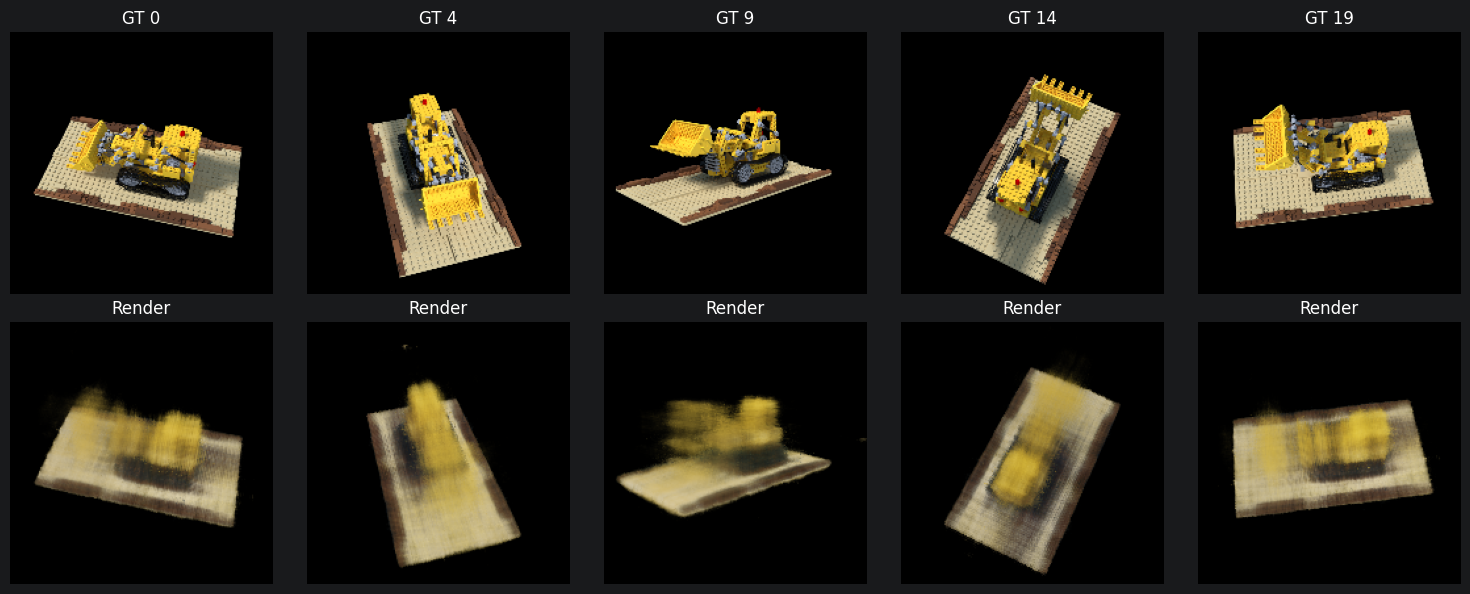

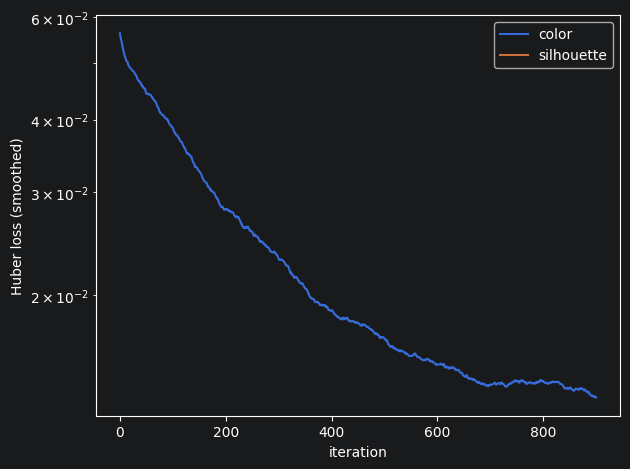

In [8]:
@torch.no_grad()
def render(cams, i):
    out, _ = renderer_full(cameras=cam_subset(cams, [i]), volumetric_function=model.batched_forward)
    return out[0, ..., :3].clamp(0, 1).cpu().numpy()


# for evaluation: predictions + ground truth for every test view
predictions = np.stack([render(test_cams, i) for i in range(len(test_cams))])
targets = test_images.cpu().numpy()
np.savez_compressed(f"{RESULTS}/lego_test_images.npz", predictions=predictions, targets=targets)

# renders vs ground truth
show = np.linspace(0, len(predictions) - 1, 5).astype(int)
fig, ax = plt.subplots(2, 5, figsize=(15, 6))
for col, k in enumerate(show):
    ax[0, col].imshow(targets[k])
    ax[0, col].set_title(f"GT {k}")
    ax[1, col].imshow(predictions[k])
    ax[1, col].set_title("Render")
    ax[0, col].axis("off")
    ax[1, col].axis("off")
plt.tight_layout()
plt.savefig(f"{RESULTS}/lego_comparison.png", dpi=150)
plt.show()

# loss curve
smooth = lambda x: np.convolve(x, np.ones(100) / 100, mode="valid")
plt.plot(smooth(loss_color), label="color")
plt.plot(smooth(loss_sil), label="silhouette")
plt.yscale("log")
plt.xlabel("iteration")
plt.ylabel("Huber loss (smoothed)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{RESULTS}/lego_loss.png", dpi=150)
plt.show()